[0 1 1 ... 1 0 1]
[0 1 1 ... 1 0 1]
Length: 81 | expected: 81
All finite (no nan/inf): True
Sum of squares: 1.0 | expected: 1.0
Peak index: 40 | expected: 40
Symmetric: True
Combined pulse at center: 1.0 | expected: ~1.0
Largest value at other symbol instants: 0.005816568303543849 | expected: small, ~1e-3 or less


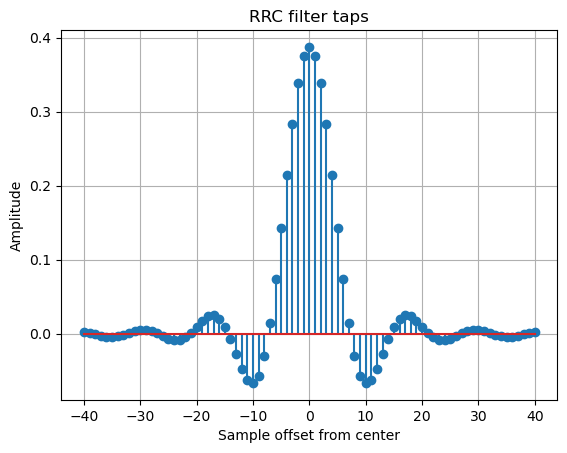

Length: 400080 | expected: 400080
Biggest Difference:  0.019330036865469875


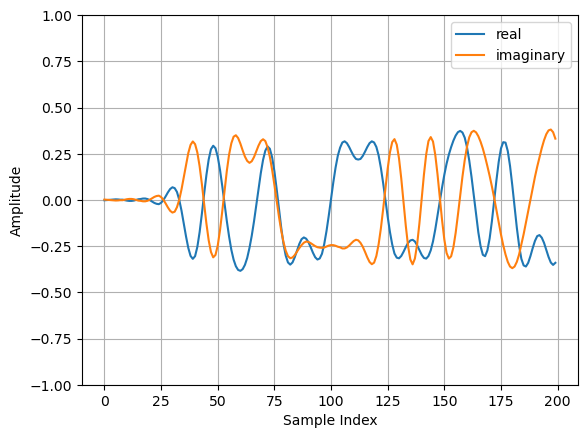

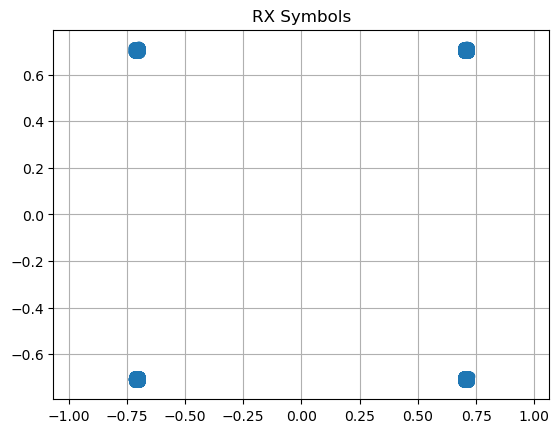

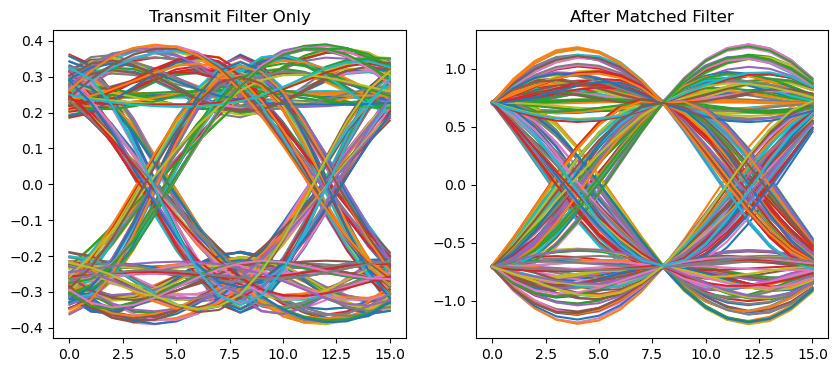

In [2]:
# Parameters
import numpy as np
import matplotlib.pyplot as plt

samples_per_symbol = 8
rolloff = 0.35
filter_span = 10

rng = np.random.default_rng(seed=42)
bits = rng.integers(0, 2, size = 100000)
# Transmitter
pairs = bits.reshape(-1, 2)
signed_pairs = 1 - 2 * pairs
pairs_left = signed_pairs[:, 0]
pairs_right = signed_pairs[:, 1]

QPSK_mapped = (pairs_right + 1j * pairs_left) / np.sqrt(2)

QPSK_upsampled = np.zeros(samples_per_symbol * QPSK_mapped.size, dtype=complex)
QPSK_upsampled[::samples_per_symbol] = QPSK_mapped

# Channel



# Receiver
def demapper(mapped_symbols):
    real_nums = mapped_symbols.real
    imaginary_nums = mapped_symbols.imag

    first_bit = (imaginary_nums < 0).astype(int)
    second_bit = (real_nums < 0).astype(int)
    demapped = np.column_stack((first_bit, second_bit))
    demapped_bits = demapped.flatten()
    return demapped_bits

def RRC(sps, roll_off, span):
    half_span = span // 2
    time_axis = np.arange(-half_span * sps, half_span * sps + 1) / sps

    numerator = np.sin(np.pi * time_axis * (1 - roll_off)) + (
        4 * roll_off * time_axis * np.cos(np.pi * time_axis * (1 + roll_off)))
    denominator = np.pi * time_axis * (1 - (4 * roll_off * time_axis) ** 2)
    with np.errstate(divide='ignore', invalid='ignore'):
        rrc = numerator / denominator

    rrc[np.isclose(time_axis, 0)] = 1 - roll_off + (4 * roll_off) / np.pi
    rrc[np.isclose(np.abs(time_axis), (1/(4 * roll_off)))] = (roll_off / np.sqrt(2)) * (
        (1 + 2 / np.pi) * np.sin(np.pi / (4 * roll_off)) + (1 - 2 / np.pi) * np.cos(np.pi / (4 * roll_off)))

    return rrc / np.sqrt(np.sum(rrc ** 2))


taps = RRC(samples_per_symbol, rolloff, filter_span)
filtered = np.convolve(taps, QPSK_upsampled)
received = filtered
matched = np.convolve(received, taps)
rx_symbols = matched[80::samples_per_symbol][:QPSK_mapped.size]
print(demapper(rx_symbols))
print(bits)

# Plots
expected_len = filter_span * samples_per_symbol + 1
center = len(taps) // 2

#Basic shape and values of RRC
print("Length:", len(taps), "| expected:", expected_len)
print("All finite (no nan/inf):", np.all(np.isfinite(taps)))
print("Sum of squares:", np.sum(taps**2), "| expected: 1.0")
print("Peak index:", np.argmax(taps), "| expected:", center)
print("Symmetric:", np.allclose(taps, taps[::-1]))

#RRC Convolved
combined = np.convolve(taps, taps)
mid = len(combined) // 2
offsets = np.arange(1, filter_span + 1) * samples_per_symbol
neighbors = np.concatenate((combined[mid - offsets], combined[mid + offsets]))
print("Combined pulse at center:", combined[mid], "| expected: ~1.0")
print("Largest value at other symbol instants:", np.max(np.abs(neighbors)), "| expected: small, ~1e-3 or less")

#Plot of the taps
plt.stem(np.arange(len(taps)) - center, taps)
plt.xlabel("Sample offset from center")
plt.ylabel("Amplitude")
plt.title("RRC filter taps")
plt.grid(True)
plt.show()

#Filtered Check
print("Length:", len(filtered), "| expected:", QPSK_upsampled.size + taps.size - 1)
print("Biggest Difference: ", np.max(np.abs(rx_symbols - QPSK_mapped)))
plt.plot(filtered[:200].real, label='real')
plt.plot(filtered[:200].imag, label='imaginary')
plt.ylim(-1, 1)
plt.legend()
plt.grid(True)
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.show()

#RX
plt.scatter(rx_symbols.real, rx_symbols.imag)
plt.axis('equal')
plt.grid(True)
plt.title("RX Symbols")
plt.show()

#Matched vs Filtered
fig, plots = plt.subplots(1,2, figsize=(10,4))
filter_start = (len(taps) - 1) // 2 + samples_per_symbol * 10 - samples_per_symbol
filter_slice = filtered.real[filter_start:filter_start + 300 * 2 * samples_per_symbol]
filter_reshaped = filter_slice.reshape(-1, 2 * samples_per_symbol)
plots[0].set_title('Transmit Filter Only')
plots[0].plot(filter_reshaped.T)

match_start = len(taps) - 1 + samples_per_symbol * 10 - samples_per_symbol
match_slice = matched.real[match_start:match_start + 300 * 2 * samples_per_symbol]
match_reshaped = match_slice.reshape(-1, 2 * samples_per_symbol)
plots[1].set_title('After Matched Filter')
plots[1].plot(match_reshaped.T)
plt.show()